In [27]:
# Noise Experiment - ML2 Project
# ================================
# Extension of Moritz Wosch's Markov-Transformer framework
# Research question: How does input noise affect the Transformer's 
# ability to preserve Markov chain statistical structure?
#

In [28]:
# %% Imports and Setup
import numpy as np
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

# Training parameters (same as Moritz)
block_size = 512
batch_size = 16
learning_rate = 0.001
weight_decay = 1e-3
dropout = 0.0
vocabulary_size = 2
eval_iters = 200
eval_interval = 500

Using device: mps


In [29]:
# %% Markov chain functions (Baseline Markov-chain utilities adapted from the original framework)
# These are copied from markov_transformer.ipynb cells 7, 9, 10
 
def generate_transition_matrix(order, seed):
    if seed is not None:
        torch.manual_seed(seed)
    n_states = 2 ** order
    matrix = torch.rand((n_states, 2))
    row_sums = matrix.sum(dim=1, keepdim=True)
    matrix = matrix / row_sums
    return matrix
 
def generate_sequence(transition_matrix, order, length, seed=None):
    if seed is not None:
        torch.manual_seed(seed)
    sequence = torch.zeros(length, dtype=torch.long)
    for i in range(order):
        sequence[i] = torch.randint(0, 2, (1,))
    for i in range(order, length):
        state_idx = 0
        for j in range(order):
            state_idx = state_idx * 2 + sequence[i - order + j]
        probs = transition_matrix[int(state_idx)]
        sequence[i] = torch.bernoulli(probs[1])
    return sequence.tolist()
 
def estimate_matrix(sequence, order):
    num_states = 2 ** order
    counts = torch.zeros((num_states, 2))
    for i in range(len(sequence) - order):
        state = sequence[i:i + order]
        state_idx = int(''.join(map(str, state)), 2)
        next_bit = sequence[i + order]
        counts[state_idx, next_bit] += 1
    row_sums = counts.sum(dim=1, keepdim=True)
    row_sums[row_sums == 0] = 2
    transition_matrix = counts / row_sums
    return transition_matrix
 
def generate_training_data(transition_matrix, order, sequence_length, num_sequences):
    sequences = []
    for i in range(num_sequences):
        sequence = generate_sequence(transition_matrix, order, sequence_length, i)
        sequences.append(torch.tensor(sequence, dtype=torch.long))
    return sequences
 
def get_batch(sequences, split='train'):
    n = int(0.9 * len(sequences))
    data = sequences[:n] if split == 'train' else sequences[n:]
    while True:
        seq_indices = torch.randint(len(data), (batch_size,))
        x_batch = []
        y_batch = []
        for idx in seq_indices:
            sequence = data[idx]
            if len(sequence) >= block_size + 1:
                start_idx = torch.randint(0, len(sequence) - block_size, (1,))
                x = sequence[start_idx:start_idx + block_size]
                y = sequence[start_idx + 1:start_idx + block_size + 1]
                x_batch.append(x)
                y_batch.append(y)
        if len(x_batch) > 0:
            x_batch = torch.stack(x_batch)
            y_batch = torch.stack(y_batch)
            return x_batch.to(device), y_batch.to(device)
 
@torch.no_grad()
def estimate_loss(model, sequences):
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(sequences, split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out
 
def kl_divergence(chain1, chain2, epsilon=1e-10):
    defined_states = torch.sum(chain2, dim=1) > 0
    p = chain1[defined_states] + epsilon
    q = chain2[defined_states] + epsilon
    p = p / p.sum(dim=1, keepdim=True)
    q = q / q.sum(dim=1, keepdim=True)
    kl_div = torch.sum(p * torch.log(p / q))
    return kl_div.item()
 
def mean_error(chain1, chain2):
    defined_states = torch.sum(chain2, dim=1) > 0
    p = chain1[defined_states]
    q = chain2[defined_states]
    abs_diff = torch.abs(p - q)
    return torch.mean(abs_diff).item()

In [30]:
# %% Transformer model (Baseline Markov-chain utilities adapted from the original framework)
 
class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)
 
    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)
        q = self.query(x)
        wei = q @ k.transpose(-2, -1) * C ** -0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)
        out = wei @ v
        return out
 
class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)
 
    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out
 
class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )
    def forward(self, x):
        return self.net(x)
 
class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)
 
    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x
 
class BinaryTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding = nn.Embedding(vocabulary_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocabulary_size)
 
    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)
        pos_emb = self.position_embedding(torch.arange(T, device=device))
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B * T, C)
            targets = targets.view(B * T)
            loss = F.cross_entropy(logits, targets)
        return logits, loss
 
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]
            logits, loss = self(idx_cond)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

In [31]:
# %% Training function (unchanged from Moritz)
 
def train_model(order, number, num_iterations, seed, sequence_length, num_sequences):
    model = BinaryTransformer().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    
    transition_matrix = generate_transition_matrix(order, seed)
    sequences = generate_training_data(transition_matrix, order, sequence_length, num_sequences)
    
    history = {'train': [], 'val': []}
    
    for iter in range(num_iterations):
        xb, yb = get_batch(sequences, 'train')
        logits, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        
        if iter % eval_interval == 0 or iter == num_iterations - 1:
            losses = estimate_loss(model, sequences)
            history['train'].append(losses['train'].item())
            history['val'].append(losses['val'].item())
            print(f"  iter {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")
    
    # Save model
    base_path = Path("models")
    base_path.mkdir(exist_ok=True)
    torch.save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
    }, f'models/model{order}_{number}.pt')
    
    return {
        'order': order,
        'number': number,
        'seed': seed,
        'transition_matrix': transition_matrix.tolist(),
        'history': history,
    }

In [32]:
# %% Noise injection function (BIT-FLIP PERTURBATION EXPERIMENT)
def add_noise(sequence, flip_probability):
    """
    Add bit-flip noise to a binary sequence.
    Each bit is flipped with probability p.
    p=0.0 means no noise, p=0.5 means completely random.
    """
    noisy = sequence.copy()
    for i in range(len(noisy)):
        if np.random.random() < flip_probability:
            noisy[i] = 1 - noisy[i]
    return noisy

In [33]:
# %% Train Order 1
n_head = 1
n_layer = 2
n_embd = 16
 
print("="*60)
print("TRAINING ORDER 1")
print("="*60)
models_order1 = []
for number, seed in enumerate([87, 88, 89, 90, 91], 1):
    print(f"\nModel 1_{number} (seed={seed})")
    info = train_model(order=1, number=number, num_iterations=5000,
                       seed=seed, sequence_length=1000, num_sequences=500)
    models_order1.append(info)
print("\nOrder 1 done!")

TRAINING ORDER 1

Model 1_1 (seed=87)
  iter 0: train loss 0.7187, val loss 0.7194
  iter 500: train loss 0.4800, val loss 0.4805
  iter 1000: train loss 0.4798, val loss 0.4802
  iter 1500: train loss 0.4798, val loss 0.4803
  iter 2000: train loss 0.4796, val loss 0.4798
  iter 2500: train loss 0.4795, val loss 0.4799
  iter 3000: train loss 0.4799, val loss 0.4802
  iter 3500: train loss 0.4796, val loss 0.4801
  iter 4000: train loss 0.4797, val loss 0.4800
  iter 4500: train loss 0.4797, val loss 0.4801
  iter 4999: train loss 0.4798, val loss 0.4802

Model 1_2 (seed=88)
  iter 0: train loss 0.8095, val loss 0.8085
  iter 500: train loss 0.6696, val loss 0.6690
  iter 1000: train loss 0.6693, val loss 0.6687
  iter 1500: train loss 0.6692, val loss 0.6688
  iter 2000: train loss 0.6694, val loss 0.6689
  iter 2500: train loss 0.6693, val loss 0.6692
  iter 3000: train loss 0.6691, val loss 0.6688
  iter 3500: train loss 0.6692, val loss 0.6690
  iter 4000: train loss 0.6691, val l

In [34]:
# %% Train Order 2
n_head = 1
n_layer = 2
n_embd = 64
 
print("="*60)
print("TRAINING ORDER 2")
print("="*60)
models_order2 = []
for number, seed in enumerate([92, 93, 94, 95, 96], 1):
    print(f"\nModel 2_{number} (seed={seed})")
    info = train_model(order=2, number=number, num_iterations=5000,
                       seed=seed, sequence_length=1000, num_sequences=500)
    models_order2.append(info)
print("\nOrder 2 done!")

TRAINING ORDER 2

Model 2_1 (seed=92)
  iter 0: train loss 0.6554, val loss 0.6557
  iter 500: train loss 0.5708, val loss 0.5691
  iter 1000: train loss 0.5417, val loss 0.5411
  iter 1500: train loss 0.5157, val loss 0.5150
  iter 2000: train loss 0.4881, val loss 0.4879
  iter 2500: train loss 0.4798, val loss 0.4791
  iter 3000: train loss 0.4764, val loss 0.4757
  iter 3500: train loss 0.4728, val loss 0.4724
  iter 4000: train loss 0.4709, val loss 0.4702
  iter 4500: train loss 0.4702, val loss 0.4698
  iter 4999: train loss 0.4709, val loss 0.4700

Model 2_2 (seed=93)
  iter 0: train loss 0.6444, val loss 0.6452
  iter 500: train loss 0.6065, val loss 0.6077
  iter 1000: train loss 0.6064, val loss 0.6073
  iter 1500: train loss 0.6062, val loss 0.6077
  iter 2000: train loss 0.6057, val loss 0.6066
  iter 2500: train loss 0.6059, val loss 0.6066
  iter 3000: train loss 0.6067, val loss 0.6069
  iter 3500: train loss 0.6060, val loss 0.6066
  iter 4000: train loss 0.6064, val l

In [35]:
# %% Train Order 3
n_head = 1
n_layer = 3
n_embd = 64
 
print("="*60)
print("TRAINING ORDER 3")
print("="*60)
models_order3 = []
for number, seed in enumerate([97, 98, 99, 100, 101], 1):
    print(f"\nModel 3_{number} (seed={seed})")
    info = train_model(order=3, number=number, num_iterations=10000,
                       seed=seed, sequence_length=1000, num_sequences=1000)
    models_order3.append(info)
print("\nOrder 3 done!")

TRAINING ORDER 3

Model 3_1 (seed=97)
  iter 0: train loss 0.8011, val loss 0.8029
  iter 500: train loss 0.6920, val loss 0.6921
  iter 1000: train loss 0.6883, val loss 0.6887
  iter 1500: train loss 0.6774, val loss 0.6773
  iter 2000: train loss 0.6637, val loss 0.6633
  iter 2500: train loss 0.6489, val loss 0.6485
  iter 3000: train loss 0.6461, val loss 0.6462
  iter 3500: train loss 0.6446, val loss 0.6441
  iter 4000: train loss 0.6436, val loss 0.6435
  iter 4500: train loss 0.6430, val loss 0.6431
  iter 5000: train loss 0.6427, val loss 0.6422
  iter 5500: train loss 0.6425, val loss 0.6423
  iter 6000: train loss 0.6424, val loss 0.6421
  iter 6500: train loss 0.6416, val loss 0.6411
  iter 7000: train loss 0.6423, val loss 0.6418
  iter 7500: train loss 0.6424, val loss 0.6422
  iter 8000: train loss 0.6420, val loss 0.6412
  iter 8500: train loss 0.6425, val loss 0.6414
  iter 9000: train loss 0.6415, val loss 0.6412
  iter 9500: train loss 0.6420, val loss 0.6419
  iter

In [39]:
# %% Train Order 4
n_head = 1
n_layer = 3
n_embd = 64

print("TRAINING ORDER 4")
models_order4 = []
for number, seed in enumerate([102, 103, 104, 105, 106], 1):
    print(f"\nModel 4_{number} (seed={seed})")
    info = train_model(order=4, number=number, num_iterations=10000,
                       seed=seed, sequence_length=2000, num_sequences=1000)
    models_order4.append(info)

TRAINING ORDER 4

Model 4_1 (seed=102)
  iter 0: train loss 0.7594, val loss 0.7590
  iter 500: train loss 0.6523, val loss 0.6526
  iter 1000: train loss 0.5195, val loss 0.5200
  iter 1500: train loss 0.4725, val loss 0.4731
  iter 2000: train loss 0.4590, val loss 0.4604
  iter 2500: train loss 0.4578, val loss 0.4581
  iter 3000: train loss 0.4557, val loss 0.4571
  iter 3500: train loss 0.4542, val loss 0.4557
  iter 4000: train loss 0.4526, val loss 0.4536
  iter 4500: train loss 0.4515, val loss 0.4525
  iter 5000: train loss 0.4529, val loss 0.4535
  iter 5500: train loss 0.4516, val loss 0.4530
  iter 6000: train loss 0.4511, val loss 0.4524
  iter 6500: train loss 0.4520, val loss 0.4522
  iter 7000: train loss 0.4497, val loss 0.4509
  iter 7500: train loss 0.4502, val loss 0.4516
  iter 8000: train loss 0.4501, val loss 0.4513
  iter 8500: train loss 0.4503, val loss 0.4511
  iter 9000: train loss 0.4505, val loss 0.4523
  iter 9500: train loss 0.4497, val loss 0.4521
  ite

In [ ]:
# %% Verify: test without noise first (reproduce Moritz's baseline) (can be skipped - only for sanity check)
 
print("Testing trained models WITHOUT noise (Moritz's baseline)...")
output_lengths = [500, 1000, 2000, 5000]
test_seeds = [111, 112, 113, 114, 115]
 
baseline_results = []
for model_info in models_trained:
    order = model_info['order']
    number = model_info['number']
    transition_matrix = torch.tensor(model_info['transition_matrix'])
    
    for output_length in output_lengths:
        klds = []
        maes = []
        for seed in test_seeds:
            # Generate output from Transformer
            output = []
            model = BinaryTransformer().to(device)
            model.eval()
            checkpoint = torch.load(f'models/model{order}_{number}.pt', weights_only=True)
            model.load_state_dict(checkpoint['model_state_dict'])
            
            context = torch.tensor(generate_sequence(transition_matrix, order, 50, seed))
            context = context.unsqueeze(0).to(device)
            with torch.no_grad():
                generated = model.generate(context, output_length)
            output = generated.tolist()[0][50:]
            
            # Estimate transition matrix from output
            estimated = estimate_matrix(output, order)
            klds.append(kl_divergence(transition_matrix, estimated))
            maes.append(mean_error(transition_matrix, estimated))
        
        baseline_results.append({
            'order': order, 'number': number,
            'output_length': output_length,
            'kld_mean': np.mean(klds), 'kld_std': np.std(klds),
            'mae_mean': np.mean(maes), 'mae_std': np.std(maes),
        })
 
print("\nBaseline results (no noise):")
print(f"{'Length':<10} {'KLD (mean±std)':<25} {'MAE (mean±std)':<25}")
print("-" * 60)
for length in output_lengths:
    subset = [r for r in baseline_results if r['output_length'] == length]
    kld_mean = np.mean([r['kld_mean'] for r in subset])
    kld_std = np.mean([r['kld_std'] for r in subset])
    mae_mean = np.mean([r['mae_mean'] for r in subset])
    mae_std = np.mean([r['mae_std'] for r in subset])
    print(f"{length:<10} {kld_mean:.4f} ± {kld_std:.4f}          {mae_mean:.4f} ± {mae_std:.4f}")
 

In [40]:
# %% Run noise experiment for all orders
 
print("="*60)
print("NOISE EXPERIMENT")
print("="*60)
 
noise_levels = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]
output_length = 1000
test_seeds = [111, 112, 113, 114, 115]
 
# Config: order -> (model_list, n_head, n_layer, n_embd)
order_configs = {
    1: (models_order1, 1, 2, 16),
    2: (models_order2, 1, 2, 64),
    3: (models_order3, 1, 3, 64),
    4: (models_order4, 1, 3, 64),
}
 
all_noise_results = {}
 
for order, (model_list, nh, nl, ne) in order_configs.items():
    # Set globals for model reconstruction
    n_head = nh
    n_layer = nl
    n_embd = ne
 
    all_noise_results[order] = {'model_based': [], 'algorithmic': []}
 
    for model_info in model_list:
        number = model_info['number']
        transition_matrix = torch.tensor(model_info['transition_matrix'])
 
        # Load trained model
        model = BinaryTransformer().to(device)
        model.eval()
        checkpoint = torch.load(f'models/model{order}_{number}.pt', weights_only=True)
        model.load_state_dict(checkpoint['model_state_dict'])
 
        for p in noise_levels:
            mb_klds = []
            al_klds = []
            mb_maes = []
            al_maes = []
 
            for seed in test_seeds:
                clean_sequence = generate_sequence(transition_matrix, order, output_length, seed)
 
                # === MODEL-BASED: noise on sequence, estimate directly ===
                noisy_sequence = add_noise(clean_sequence, p)
                estimated_mb = estimate_matrix(noisy_sequence, order)
                mb_klds.append(kl_divergence(transition_matrix, estimated_mb))
                mb_maes.append(mean_error(transition_matrix, estimated_mb))
 
                # === ALGORITHMIC: noisy context, Transformer generates ===
                clean_context = generate_sequence(transition_matrix, order, 50, seed)
                noisy_context = add_noise(clean_context, p)
                context_tensor = torch.tensor(noisy_context, dtype=torch.long).unsqueeze(0).to(device)
 
                with torch.no_grad():
                    generated = model.generate(context_tensor, output_length)
                output = generated.tolist()[0][50:]
 
                estimated_al = estimate_matrix(output, order)
                al_klds.append(kl_divergence(transition_matrix, estimated_al))
                al_maes.append(mean_error(transition_matrix, estimated_al))
 
            all_noise_results[order]['model_based'].append({
                'number': number, 'noise_level': p,
                'kld_mean': np.mean(mb_klds), 'kld_std': np.std(mb_klds),
                'mae_mean': np.mean(mb_maes), 'mae_std': np.std(mb_maes),
            })
            all_noise_results[order]['algorithmic'].append({
                'number': number, 'noise_level': p,
                'kld_mean': np.mean(al_klds), 'kld_std': np.std(al_klds),
                'mae_mean': np.mean(al_maes), 'mae_std': np.std(al_maes),
            })
 
        print(f"  Order {order}, Model {number} done")
 
# Save results
results_path = Path("results")
results_path.mkdir(exist_ok=True)
with open('results/noise_results_all_orders.json', 'w') as f:
    save_data = {str(k): v for k, v in all_noise_results.items()}
    json.dump(save_data, f, indent=2)
print("\nSaved to results/noise_results_all_orders.json")

NOISE EXPERIMENT
  Order 1, Model 1 done
  Order 1, Model 2 done
  Order 1, Model 3 done
  Order 1, Model 4 done
  Order 1, Model 5 done
  Order 2, Model 1 done
  Order 2, Model 2 done
  Order 2, Model 3 done
  Order 2, Model 4 done
  Order 2, Model 5 done
  Order 3, Model 1 done
  Order 3, Model 2 done
  Order 3, Model 3 done
  Order 3, Model 4 done
  Order 3, Model 5 done
  Order 4, Model 1 done
  Order 4, Model 2 done
  Order 4, Model 3 done
  Order 4, Model 4 done
  Order 4, Model 5 done

Saved to results/noise_results_all_orders.json


In [42]:
# %% Summary table
 
print("\n" + "="*60)
print("SUMMARY TABLE")
print("="*60)
 
for order in [1, 2, 3,4]:
    results = all_noise_results[order]
    print(f"\n--- Order {order} ---")
    print(f"{'Noise p':<8} {'MB KLD':<12} {'AL KLD':<12} {'MB MAE':<12} {'AL MAE':<12}")
    print("-" * 56)
    for p in noise_levels:
        mb = [r for r in results['model_based'] if r['noise_level'] == p]
        al = [r for r in results['algorithmic'] if r['noise_level'] == p]
        mb_kld = np.mean([r['kld_mean'] for r in mb])
        al_kld = np.mean([r['kld_mean'] for r in al])
        mb_mae = np.mean([r['mae_mean'] for r in mb])
        al_mae = np.mean([r['mae_mean'] for r in al])
        print(f"{p:<8} {mb_kld:<12.4f} {al_kld:<12.4f} {mb_mae:<12.4f} {al_mae:<12.4f}")


SUMMARY TABLE

--- Order 1 ---
Noise p  MB KLD       AL KLD       MB MAE       AL MAE      
--------------------------------------------------------
0.0      0.0069       0.0016       0.0139       0.0114      
0.05     0.0207       0.0016       0.0305       0.0113      
0.1      0.0461       0.0016       0.0577       0.0114      
0.15     0.0652       0.0016       0.0740       0.0113      
0.2      0.1005       0.0016       0.0986       0.0114      
0.3      0.1475       0.0016       0.1314       0.0114      
0.4      0.1929       0.0016       0.1536       0.0114      
0.5      0.2377       0.0016       0.1778       0.0113      

--- Order 2 ---
Noise p  MB KLD       AL KLD       MB MAE       AL MAE      
--------------------------------------------------------
0.0      1.8550       0.8288       0.0474       0.0584      
0.05     1.1560       0.8847       0.0783       0.0558      
0.1      0.3081       0.8850       0.1098       0.0558      
0.15     0.3536       0.8817       0.1312   

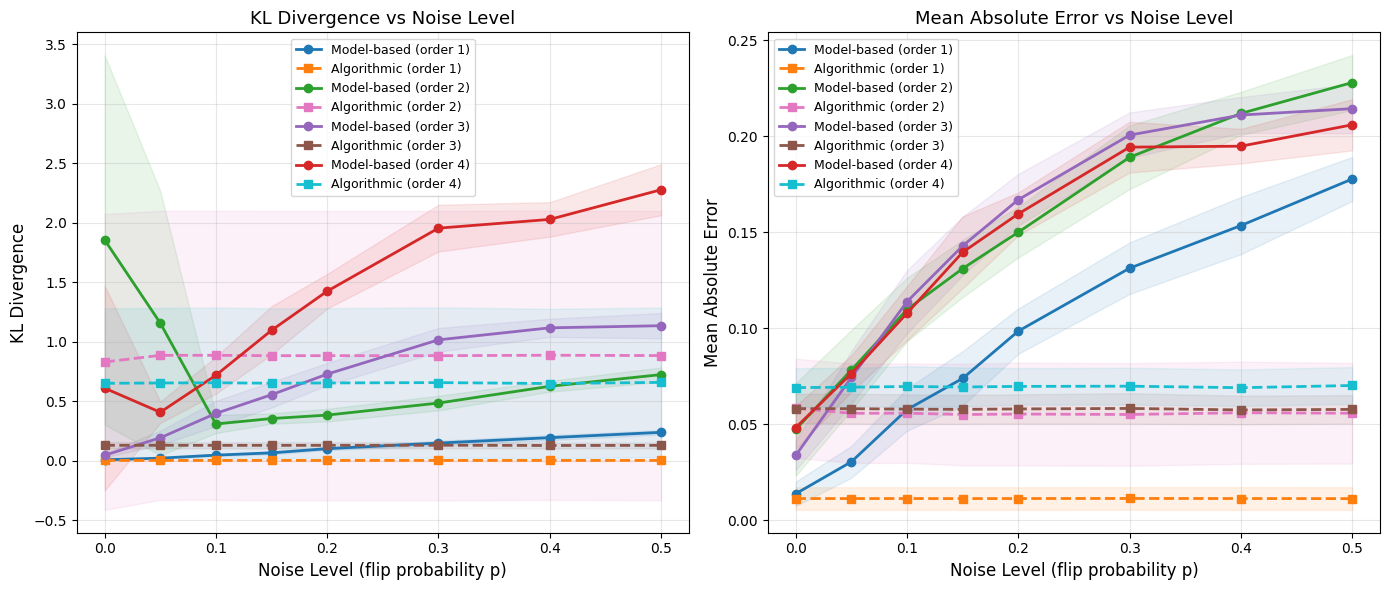

Plot saved to plots/noise_comparison_all_orders.png


In [48]:
# %% Plot 1: All orders on same axes (2 subplots)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors_mb = {1: '#1f77b4', 2: '#2ca02c', 3: '#9467bd', 4: '#d62728'}
colors_al = {1: '#ff7f0e', 2: '#e377c2', 3: '#8c564b', 4: '#17becf'}

for ax, metric, label in [(axes[0], 'kld', 'KL Divergence'), (axes[1], 'mae', 'Mean Absolute Error')]:
    for order in [1, 2, 3, 4]:
        results = all_noise_results[order]

        mb_means = []
        al_means = []
        mb_stds = []
        al_stds = []

        for p in noise_levels:
            mb_sub = [r for r in results['model_based'] if r['noise_level'] == p]
            al_sub = [r for r in results['algorithmic'] if r['noise_level'] == p]
            mb_means.append(np.mean([r[f'{metric}_mean'] for r in mb_sub]))
            al_means.append(np.mean([r[f'{metric}_mean'] for r in al_sub]))
            mb_stds.append(np.mean([r[f'{metric}_std'] for r in mb_sub]))
            al_stds.append(np.mean([r[f'{metric}_std'] for r in al_sub]))

        mb_means = np.array(mb_means)
        al_means = np.array(al_means)
        mb_stds = np.array(mb_stds)
        al_stds = np.array(al_stds)

        ax.plot(noise_levels, mb_means, 'o-', color=colors_mb[order],
                label=f'Model-based (order {order})', linewidth=2)
        ax.fill_between(noise_levels, mb_means - mb_stds, mb_means + mb_stds,
                        alpha=0.1, color=colors_mb[order])

        ax.plot(noise_levels, al_means, 's--', color=colors_al[order],
                label=f'Algorithmic (order {order})', linewidth=2)
        ax.fill_between(noise_levels, al_means - al_stds, al_means + al_stds,
                        alpha=0.1, color=colors_al[order])

    ax.set_xlabel('Noise Level (flip probability p)', fontsize=12)
    ax.set_ylabel(label, fontsize=12)
    ax.set_title(f'{label} vs Noise Level', fontsize=13)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('plots/noise_comparison_all_orders.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved to plots/noise_comparison_all_orders.png")




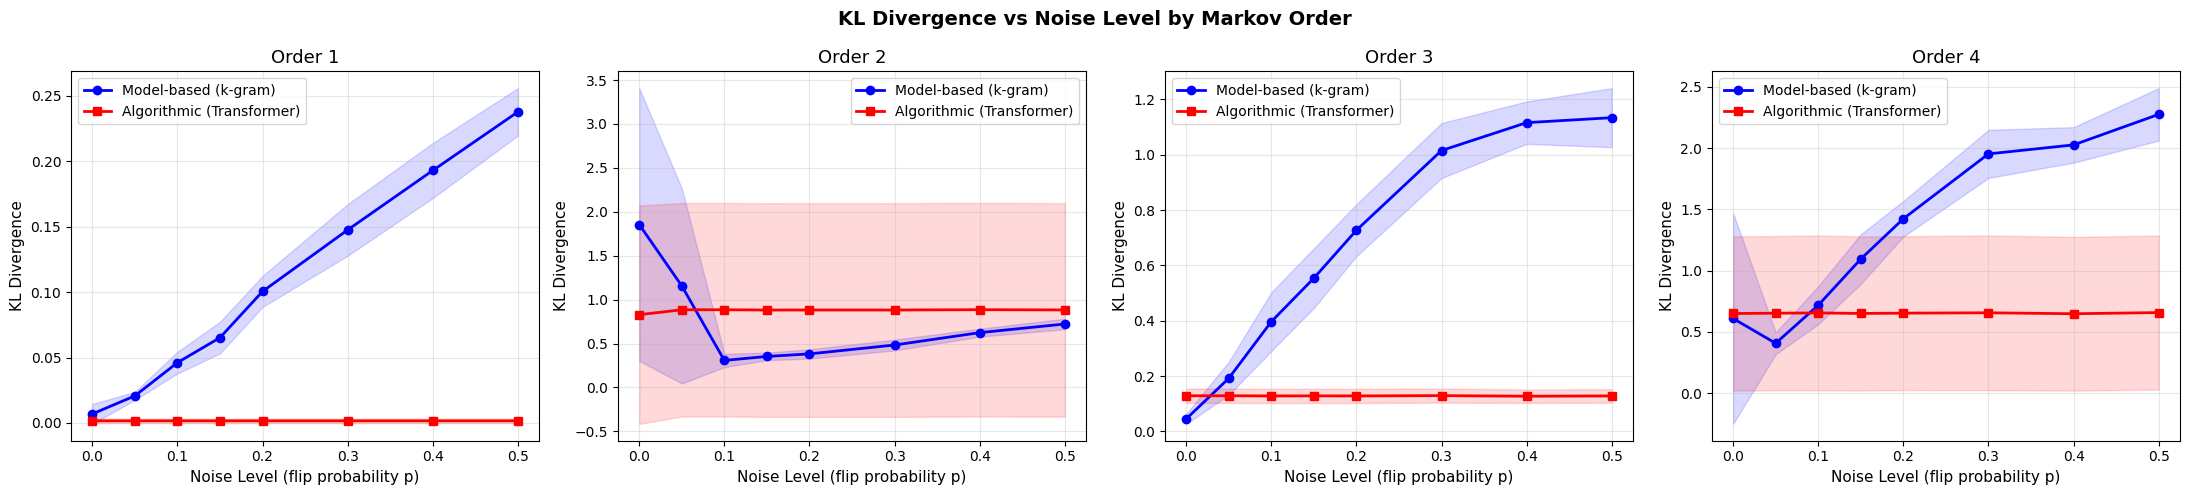

Plot saved to plots/noise_per_order.png


In [49]:
# %% Plot 2: Separate plot per order (4 subplots)

fig, axes = plt.subplots(1, 4, figsize=(22, 5))

for i, order in enumerate([1, 2, 3, 4]):
    ax = axes[i]
    results = all_noise_results[order]

    for approach, color, marker, lstyle in [
        ('model_based', 'blue', 'o', '-'),
        ('algorithmic', 'red', 's', '-'),
    ]:
        means = []
        stds = []
        for p in noise_levels:
            subset = [r for r in results[approach] if r['noise_level'] == p]
            means.append(np.mean([r['kld_mean'] for r in subset]))
            stds.append(np.mean([r['kld_std'] for r in subset]))

        means = np.array(means)
        stds = np.array(stds)
        label = 'Model-based (k-gram)' if approach == 'model_based' else 'Algorithmic (Transformer)'

        ax.plot(noise_levels, means, f'{marker}{lstyle}', color=color,
                label=label, linewidth=2)
        ax.fill_between(noise_levels, means - stds, means + stds,
                        alpha=0.15, color=color)

    ax.set_xlabel('Noise Level (flip probability p)', fontsize=11)
    ax.set_ylabel('KL Divergence', fontsize=11)
    ax.set_title(f'Order {order}', fontsize=13)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

plt.suptitle('KL Divergence vs Noise Level by Markov Order', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/noise_per_order.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved to plots/noise_per_order.png")